In [1]:
import numpy as np


# 均方误差
def mean_squard_error(y, t):
    return 0.5 * np.sum((y - t) ** 2)


t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
mean_squard_error(np.array(y), np.array(t))

y = [0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0]
mean_squard_error(np.array(y), np.array(t))

0.5975

In [2]:
# 交叉熵
def cross_entropy_error(y, t):
    delta = 1e-7  # 防止np.log(0) 变为负无限大的 -inf
    return -np.sum(t * np.log(y + delta))


t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
cross_entropy_error(np.array(y), np.array(t))

y = [0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0]
cross_entropy_error(np.array(y), np.array(t))

2.302584092994546

In [3]:
# 读取minist数据集，我之前已经下载过了
from pathlib import Path

import numpy as np

# 数据集的位置
path = Path("data/minist.npz")
with np.load(path, allow_pickle=False) as data:
    x_train = data["x_train"]
    t_train = data["y_train"]
    x_test = data["x_test"]
    t_test = data["y_test"]

# 还要reshape一下数据格式，变成以为数组
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# 把标签转换成独热编码
t_train = np.eye(10)[t_train]
t_test = np.eye(10)[t_test]

# 测试一下是否正常读取
print(x_train.shape)
print(t_train.shape)

(60000, 784)
(60000, 10)


In [4]:
# 理解独热编码的代码
import numpy as np

# 只有 0、1、2 三种标签
labels = np.array([2, 0, 1, 2])
print("原始标签：")
print(labels)

# 创建 3 × 3 的单位矩阵，dtype=int 让输出更简洁
table = np.eye(3, dtype=int)
print("\n独热编码对照表：")
print(table)

# 按照标签的值选取对应的行
one_hot = table[labels]
print("\n转换后的独热编码：")
print(one_hot)

原始标签：
[2 0 1 2]

独热编码对照表：
[[1 0 0]
 [0 1 0]
 [0 0 1]]

转换后的独热编码：
[[0 0 1]
 [1 0 0]
 [0 1 0]
 [0 0 1]]


In [5]:
# 从这个训练数据中随机抽取 10 笔数据
trian_size = x_train.shape[0]
batch_size = 10
batch_mask = np.random.choice(trian_size, batch_size)

x_batch = x_train[batch_mask]
t_batch = t_train[batch_mask]

x_batch.shape, t_batch.shape

((10, 784), (10, 10))

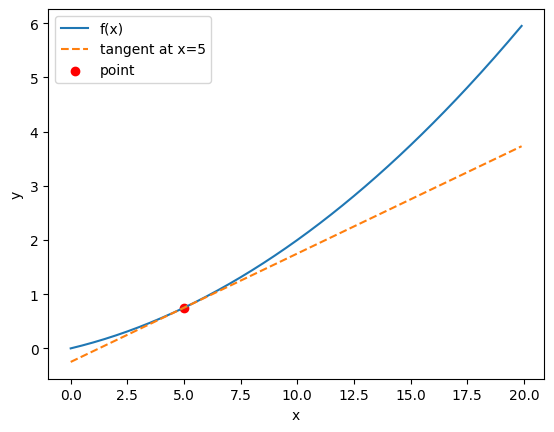

In [14]:
import matplotlib.pyplot as plt


# 导数部分
def numerical_diff(f, x):
    h = 1e-4
    return (f(x + h) - f(x - h)) / (2 * h)


def function_l(x):
    return 0.01 * x**2 + 0.1 * x


x = np.arange(0.0, 20.0, 0.1)
y = function_l(x)

# 选择切点
a = 5
slope = numerical_diff(function_l, a)  # 切线的斜率
tangent = function_l(a) + slope * (x - a)

plt.xlabel("x")
plt.ylabel("y")
plt.plot(x, y, label="f(x)")
plt.plot(x, tangent, "--", label="tangent at x=5")
plt.scatter([a], [function_l(a)], color="red", label="point")
plt.legend()
plt.show()

In [18]:
# 梯度
def numerical_gradient(f, x):
    h = 1e-4
    grad = np.zeros_like(x)  # 生成和x形状相同的数组

    for idx in range(x.size):
        tmp_val = x[idx]

        x[idx] = tmp_val + h
        fxh1 = f(x)

        x[idx] = tmp_val - h
        fxh2 = f(x)

        grad[idx] = (fxh1-fxh2) / (2*h)
        x[idx] = tmp_val #还原值

    return grad

def function_2(x):
    return x[0]**2 + x[1]**2

In [19]:
numerical_gradient(function_2,np.array([3.0,4.0]))

array([6., 8.])